# Task 2: Data Exploration
## HMS - Hotel Booking Demand

### Business Questions
- **Q1:** Which bookings will be cancelled, and should we ask those guests for a deposit?
- **Q2:** What is the expected price per night for each booking?
- **Q3:** When is the hotel fully booked, and what drives high-demand periods?

## Imports & Load Clean Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Settings
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['figure.dpi'] = 100
sns.set_theme(style="whitegrid")

# Load clean data
df = pd.read_csv('../data/hotel_bookings_clean.csv')

print(f"✅ Clean data loaded!")
print(f"📊 Shape: {df.shape}")
df.head()

✅ Clean data loaded!
📊 Shape: (86638, 36)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,adr_extreme_flag,adults_extreme_flag,country_missing,arrival_date_month_num
0,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,Transient,75.0,0,0,Check-Out,2015-07-02,0,0,0,7
1,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,Transient,75.0,0,0,Check-Out,2015-07-02,0,0,0,7
2,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,Transient,98.0,0,1,Check-Out,2015-07-03,0,0,0,7
3,Resort Hotel,0,0,2015,July,27,1,0,2,2,...,Transient,107.0,0,0,Check-Out,2015-07-03,0,0,0,7
4,Resort Hotel,0,9,2015,July,27,1,0,2,2,...,Transient,103.0,0,1,Check-Out,2015-07-03,0,0,0,7


---
## Q1: Which bookings will be cancelled?
---

📊 Overall Cancellation Rate: 26.5%

🏨 Cancellation Rate by Hotel:
hotel
City Hotel      28.8
Resort Hotel    22.9
Name: is_canceled, dtype: float64


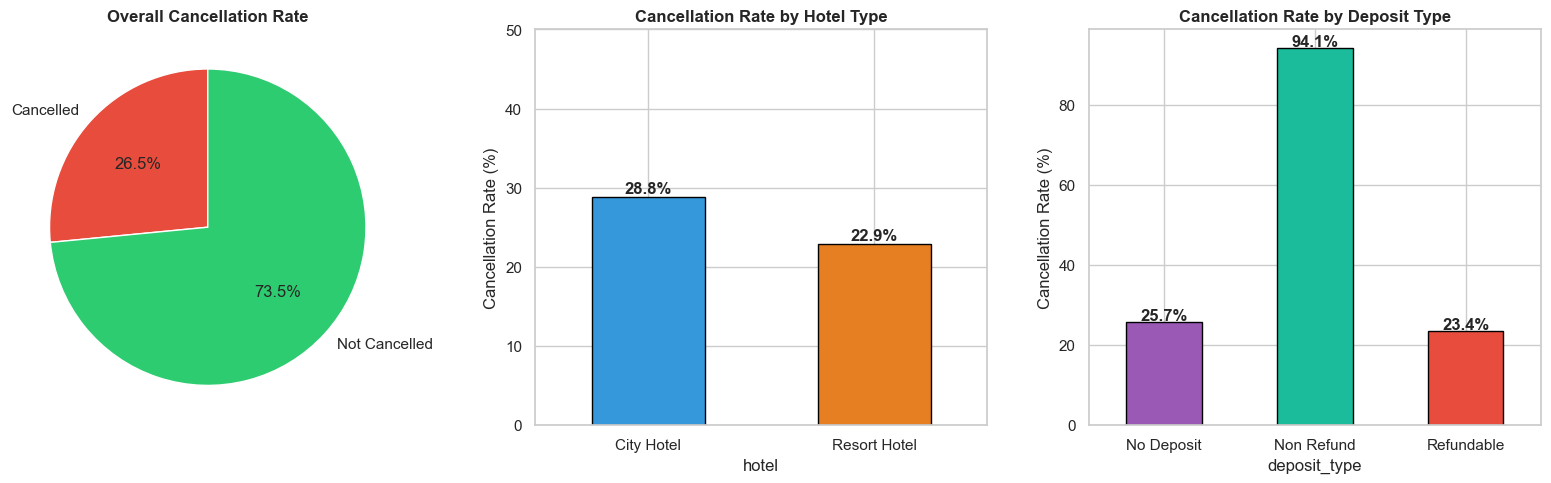

In [2]:
# Overall cancellation rate
cancel_rate = df['is_canceled'].mean() * 100
print(f"📊 Overall Cancellation Rate: {cancel_rate:.1f}%")

# By hotel type
cancel_by_hotel = df.groupby('hotel')['is_canceled'].mean() * 100
print(f"\n🏨 Cancellation Rate by Hotel:")
print(cancel_by_hotel.round(1))

# Plot
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Overall
axes[0].pie(
    [cancel_rate, 100 - cancel_rate],
    labels=['Cancelled', 'Not Cancelled'],
    colors=['#e74c3c', '#2ecc71'],
    autopct='%1.1f%%',
    startangle=90
)
axes[0].set_title('Overall Cancellation Rate', fontweight='bold')

# 2. By Hotel
cancel_by_hotel.plot(kind='bar', ax=axes[1], 
                      color=['#3498db', '#e67e22'], edgecolor='black')
axes[1].set_title('Cancellation Rate by Hotel Type', fontweight='bold')
axes[1].set_ylabel('Cancellation Rate (%)')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)
axes[1].set_ylim(0, 50)
for i, v in enumerate(cancel_by_hotel):
    axes[1].text(i, v + 0.5, f'{v:.1f}%', ha='center', fontweight='bold')

# 3. By Deposit Type
cancel_by_deposit = df.groupby('deposit_type')['is_canceled'].mean() * 100
cancel_by_deposit.plot(kind='bar', ax=axes[2],
                        color=['#9b59b6', '#1abc9c', '#e74c3c'], edgecolor='black')
axes[2].set_title('Cancellation Rate by Deposit Type', fontweight='bold')
axes[2].set_ylabel('Cancellation Rate (%)')
axes[2].set_xticklabels(axes[2].get_xticklabels(), rotation=0)
for i, v in enumerate(cancel_by_deposit):
    axes[2].text(i, v + 0.5, f'{v:.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('../slides/q1_cancellation_overview.png', bbox_inches='tight')
plt.show()

## Cancellation by Lead Time & Market Segment

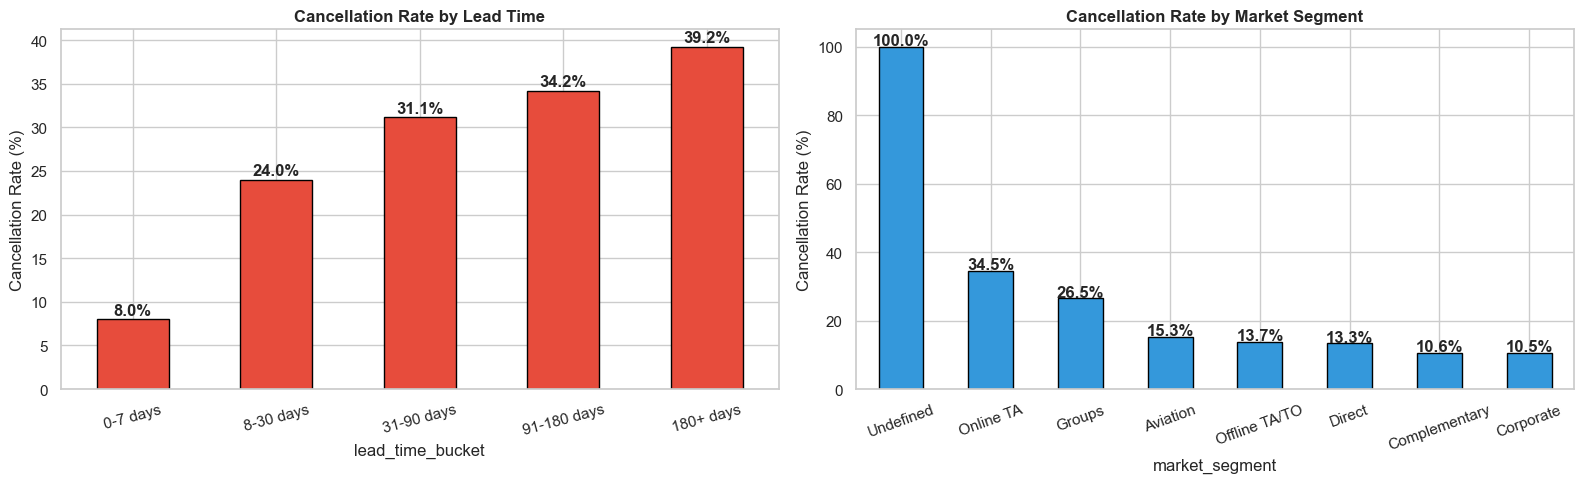

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Lead Time vs Cancellation
df['lead_time_bucket'] = pd.cut(df['lead_time'],
    bins=[0, 7, 30, 90, 180, 737],
    labels=['0-7 days', '8-30 days', '31-90 days', '91-180 days', '180+ days'])

cancel_by_lead = df.groupby('lead_time_bucket', observed=True)['is_canceled'].mean() * 100
cancel_by_lead.plot(kind='bar', ax=axes[0], color='#e74c3c', edgecolor='black')
axes[0].set_title('Cancellation Rate by Lead Time', fontweight='bold')
axes[0].set_ylabel('Cancellation Rate (%)')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=15)
for i, v in enumerate(cancel_by_lead):
    axes[0].text(i, v + 0.5, f'{v:.1f}%', ha='center', fontweight='bold')

# 2. By Market Segment
cancel_by_market = df.groupby('market_segment')['is_canceled'].mean() * 100
cancel_by_market = cancel_by_market.sort_values(ascending=False)
cancel_by_market.plot(kind='bar', ax=axes[1], color='#3498db', edgecolor='black')
axes[1].set_title('Cancellation Rate by Market Segment', fontweight='bold')
axes[1].set_ylabel('Cancellation Rate (%)')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=20)
for i, v in enumerate(cancel_by_market):
    axes[1].text(i, v + 0.5, f'{v:.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('../slides/q1_cancellation_details.png', bbox_inches='tight')
plt.show()

## Statistical Test Q1

In [4]:
print("=" * 55)
print("📐 STATISTICAL TEST: Is cancellation rate different")
print("   between City Hotel and Resort Hotel?")
print("=" * 55)

city   = df[df['hotel'] == 'City Hotel']['is_canceled']
resort = df[df['hotel'] == 'Resort Hotel']['is_canceled']

# Chi-square test
ct = pd.crosstab(df['hotel'], df['is_canceled'])
chi2, p, dof, expected = stats.chi2_contingency(ct)

print(f"\n🏨 City Hotel   cancellation rate: {city.mean()*100:.1f}%")
print(f"🏖️  Resort Hotel cancellation rate: {resort.mean()*100:.1f}%")
print(f"\nChi-square statistic : {chi2:.2f}")
print(f"P-value              : {p:.6f}")

if p < 0.05:
    print(f"\n✅ Result is SIGNIFICANT (p < 0.05)")
    print(f"   The difference is REAL, not by chance!")
else:
    print(f"\n❌ Result is NOT significant")

📐 STATISTICAL TEST: Is cancellation rate different
   between City Hotel and Resort Hotel?

🏨 City Hotel   cancellation rate: 28.8%
🏖️  Resort Hotel cancellation rate: 22.9%

Chi-square statistic : 364.36
P-value              : 0.000000

✅ Result is SIGNIFICANT (p < 0.05)
   The difference is REAL, not by chance!


---
## Q2: What is the expected price per night (ADR)?
---

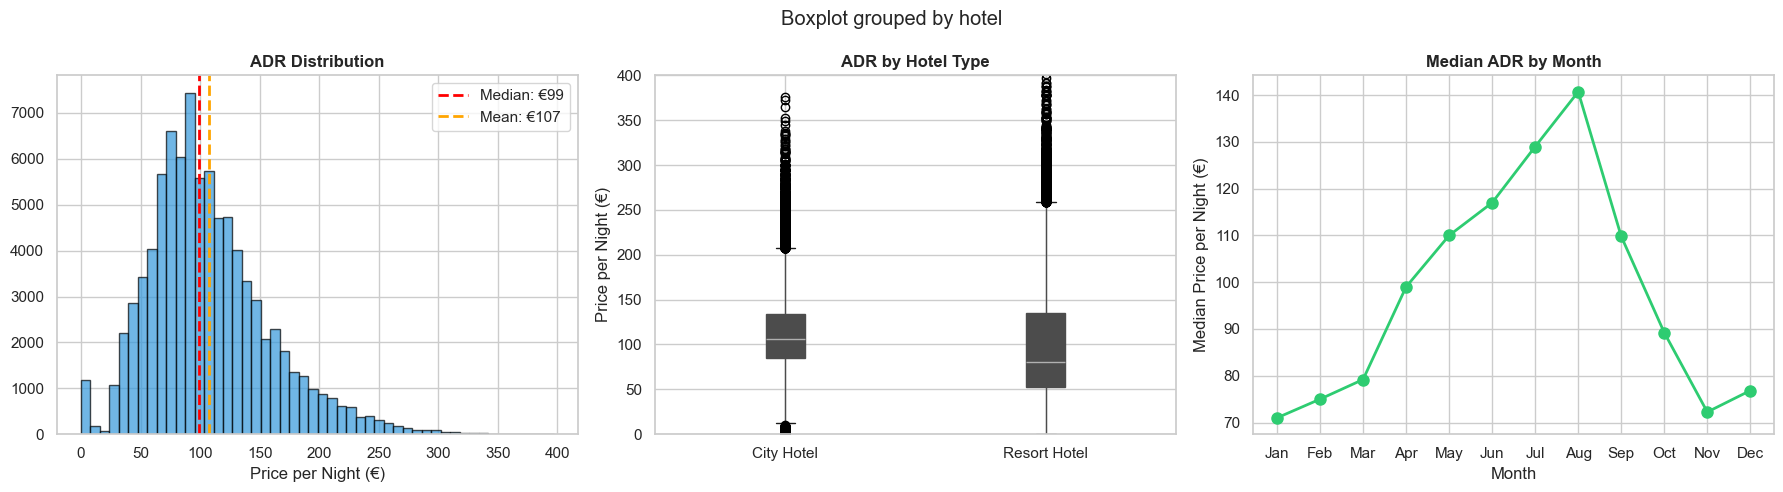

📊 ADR Summary:
   Mean   : €107.25
   Median : €99.00
   Min    : €0.00
   Max    : €5400.00


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. ADR Distribution
axes[0].hist(df[df['adr'] < 400]['adr'], bins=50, 
             color='#3498db', edgecolor='black', alpha=0.7)
axes[0].axvline(df['adr'].median(), color='red', 
                linestyle='--', linewidth=2, label=f"Median: €{df['adr'].median():.0f}")
axes[0].axvline(df['adr'].mean(), color='orange', 
                linestyle='--', linewidth=2, label=f"Mean: €{df['adr'].mean():.0f}")
axes[0].set_title('ADR Distribution', fontweight='bold')
axes[0].set_xlabel('Price per Night (€)')
axes[0].legend()

# 2. ADR by Hotel Type
df.boxplot(column='adr', by='hotel', ax=axes[1],
           patch_artist=True)
axes[1].set_title('ADR by Hotel Type', fontweight='bold')
axes[1].set_xlabel('')
axes[1].set_ylabel('Price per Night (€)')
axes[1].set_ylim(0, 400)

# 3. ADR by Month
adr_by_month = df.groupby('arrival_date_month_num')['adr'].median()
adr_by_month.plot(kind='line', ax=axes[2], marker='o', 
                   color='#2ecc71', linewidth=2, markersize=8)
axes[2].set_title('Median ADR by Month', fontweight='bold')
axes[2].set_xlabel('Month')
axes[2].set_ylabel('Median Price per Night (€)')
axes[2].set_xticks(range(1, 13))
axes[2].set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun',
                          'Jul','Aug','Sep','Oct','Nov','Dec'])

plt.tight_layout()
plt.savefig('../slides/q2_adr_analysis.png', bbox_inches='tight')
plt.show()

print(f"📊 ADR Summary:")
print(f"   Mean   : €{df['adr'].mean():.2f}")
print(f"   Median : €{df['adr'].median():.2f}")
print(f"   Min    : €{df['adr'].min():.2f}")
print(f"   Max    : €{df['adr'].max():.2f}")

## ADR by Meal & Room Type

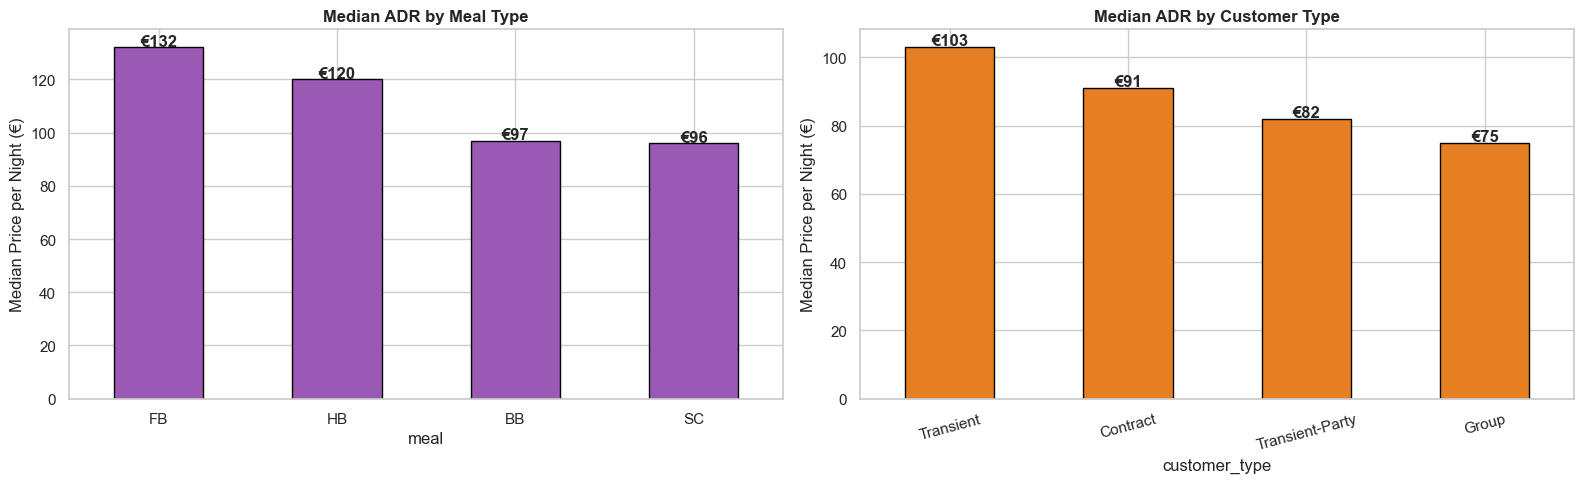

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. ADR by Meal Type
adr_by_meal = df.groupby('meal')['adr'].median().sort_values(ascending=False)
adr_by_meal.plot(kind='bar', ax=axes[0], 
                  color='#9b59b6', edgecolor='black')
axes[0].set_title('Median ADR by Meal Type', fontweight='bold')
axes[0].set_ylabel('Median Price per Night (€)')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=0)
for i, v in enumerate(adr_by_meal):
    axes[0].text(i, v + 0.5, f'€{v:.0f}', ha='center', fontweight='bold')

# 2. ADR by Customer Type
adr_by_customer = df.groupby('customer_type')['adr'].median().sort_values(ascending=False)
adr_by_customer.plot(kind='bar', ax=axes[1], 
                      color='#e67e22', edgecolor='black')
axes[1].set_title('Median ADR by Customer Type', fontweight='bold')
axes[1].set_ylabel('Median Price per Night (€)')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=15)
for i, v in enumerate(adr_by_customer):
    axes[1].text(i, v + 0.5, f'€{v:.0f}', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('../slides/q2_adr_by_type.png', bbox_inches='tight')
plt.show()

---
## Q3: When is the hotel fully booked & what drives demand?
---

## Demand Analysis

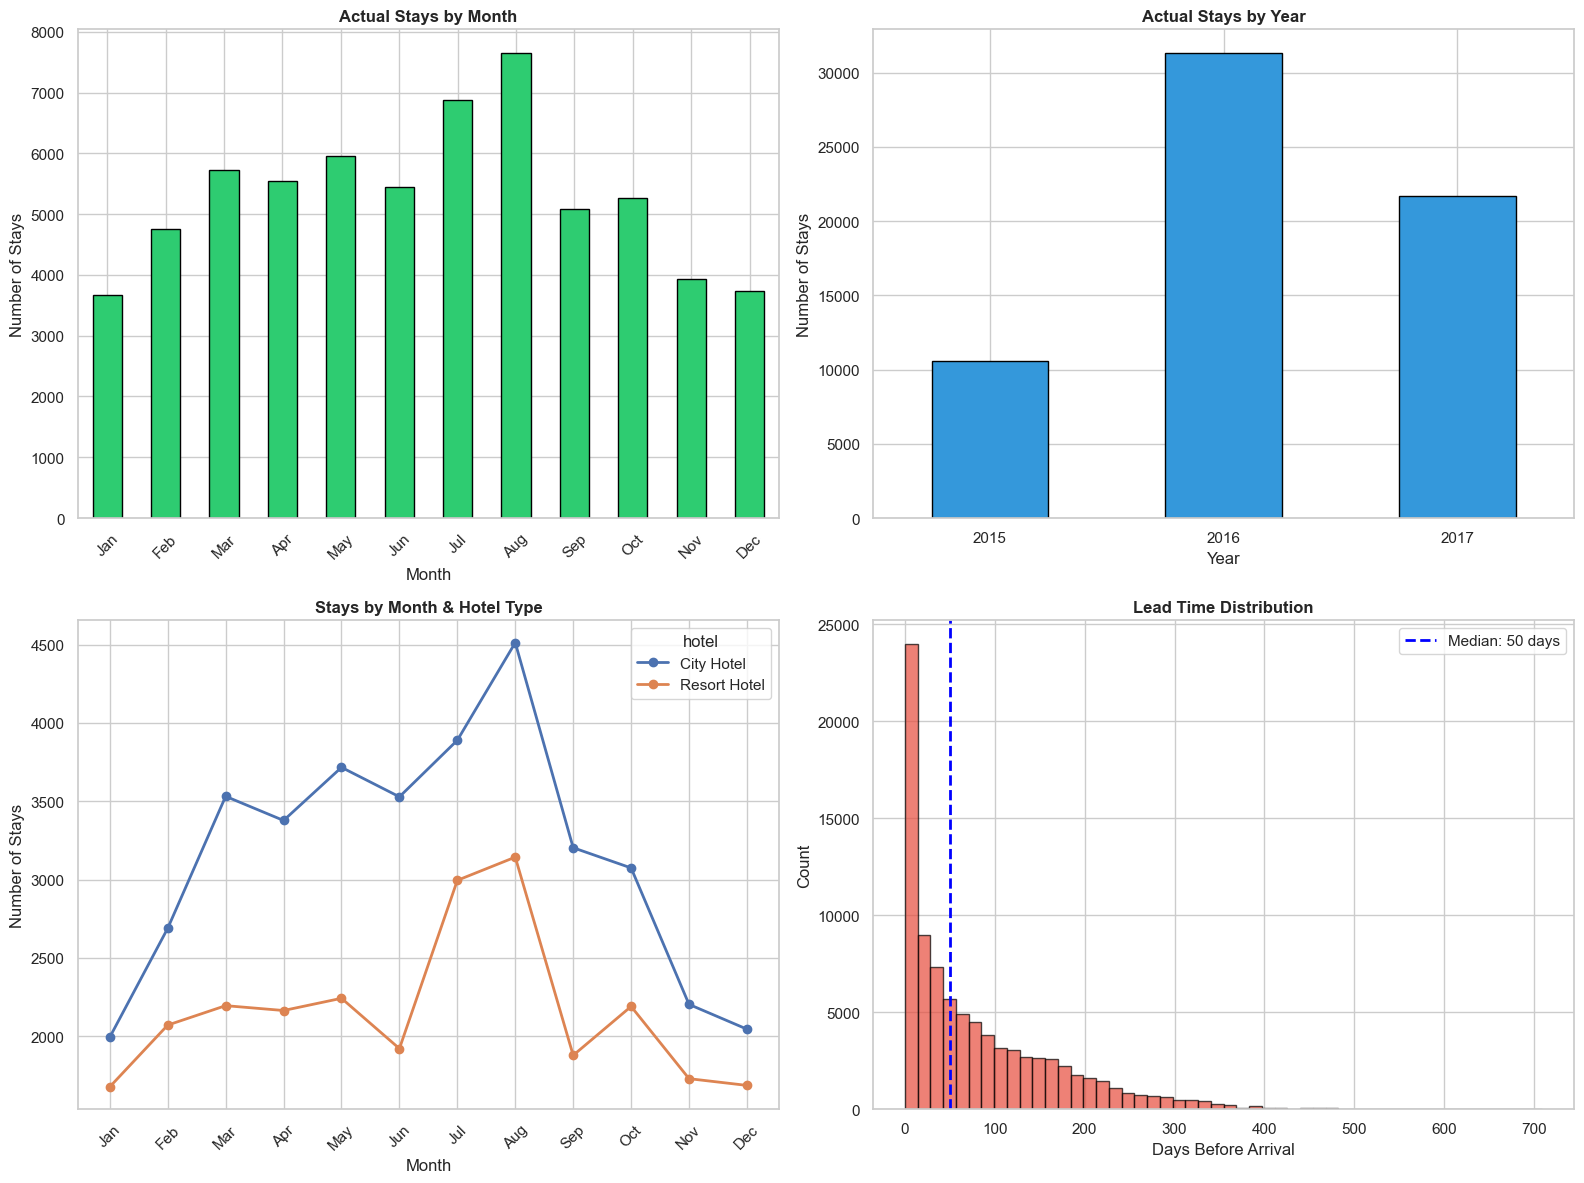

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Bookings by Month
bookings_by_month = df[df['is_canceled']==0].groupby(
    'arrival_date_month_num').size()
bookings_by_month.plot(kind='bar', ax=axes[0,0], 
                        color='#2ecc71', edgecolor='black')
axes[0,0].set_title('Actual Stays by Month', fontweight='bold')
axes[0,0].set_xlabel('Month')
axes[0,0].set_ylabel('Number of Stays')
axes[0,0].set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun',
                             'Jul','Aug','Sep','Oct','Nov','Dec'], rotation=45)

# 2. Bookings by Year
bookings_by_year = df[df['is_canceled']==0].groupby(
    'arrival_date_year').size()
bookings_by_year.plot(kind='bar', ax=axes[0,1], 
                       color='#3498db', edgecolor='black')
axes[0,1].set_title('Actual Stays by Year', fontweight='bold')
axes[0,1].set_xlabel('Year')
axes[0,1].set_ylabel('Number of Stays')
axes[0,1].set_xticklabels(axes[0,1].get_xticklabels(), rotation=0)

# 3. Bookings by Hotel & Month
pivot = df[df['is_canceled']==0].groupby(
    ['arrival_date_month_num', 'hotel']).size().unstack()
pivot.plot(kind='line', ax=axes[1,0], marker='o', linewidth=2)
axes[1,0].set_title('Stays by Month & Hotel Type', fontweight='bold')
axes[1,0].set_xlabel('Month')
axes[1,0].set_ylabel('Number of Stays')
axes[1,0].set_xticks(range(1, 13))
axes[1,0].set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun',
                             'Jul','Aug','Sep','Oct','Nov','Dec'], rotation=45)

# 4. Lead Time Distribution
axes[1,1].hist(df['lead_time'], bins=50, 
               color='#e74c3c', edgecolor='black', alpha=0.7)
axes[1,1].axvline(df['lead_time'].median(), color='blue',
                   linestyle='--', linewidth=2, 
                   label=f"Median: {df['lead_time'].median():.0f} days")
axes[1,1].set_title('Lead Time Distribution', fontweight='bold')
axes[1,1].set_xlabel('Days Before Arrival')
axes[1,1].set_ylabel('Count')
axes[1,1].legend()

plt.tight_layout()
plt.savefig('../slides/q3_demand_analysis.png', bbox_inches='tight')
plt.show()

## Statistical Test Q3

In [8]:
print("=" * 55)
print("📐 STATISTICAL TEST: Is summer ADR higher than winter?")
print("=" * 55)

summer = df[df['arrival_date_month_num'].isin([6,7,8])]['adr']
winter = df[df['arrival_date_month_num'].isin([12,1,2])]['adr']

t_stat, p_val = stats.ttest_ind(summer, winter)

print(f"\n☀️  Summer median ADR: €{summer.median():.2f}")
print(f"❄️  Winter median ADR: €{winter.median():.2f}")
print(f"\nT-statistic : {t_stat:.2f}")
print(f"P-value     : {p_val:.6f}")

if p_val < 0.05:
    print(f"\n✅ SIGNIFICANT: Summer IS more expensive than winter!")
else:
    print(f"\n❌ NOT significant")

📐 STATISTICAL TEST: Is summer ADR higher than winter?

☀️  Summer median ADR: €129.50
❄️  Winter median ADR: €74.80

T-statistic : 127.90
P-value     : 0.000000

✅ SIGNIFICANT: Summer IS more expensive than winter!



## Top 5 Business Findings

## Finding 1 - Special Requests

🔍 FINDING 1: Special Requests & Cancellation


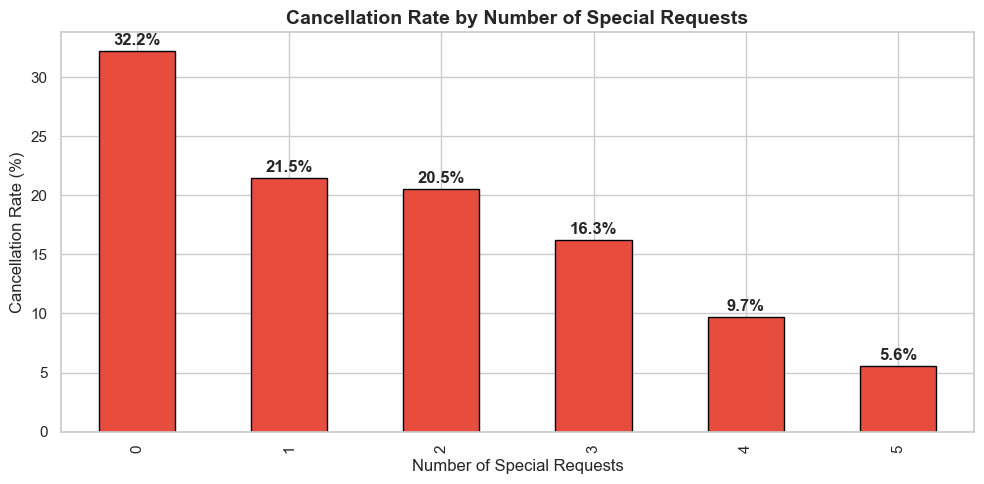


📌 Cancellation with 0 special requests : 32.2%
📌 Cancellation with 1+ special requests: 20.8%

💡 ACTION: Guests with no special requests are 1.5x more likely to cancel!
   → Ask them for a deposit or send a reminder


In [9]:
print("=" * 55)
print("🔍 FINDING 1: Special Requests & Cancellation")
print("=" * 55)

cancel_by_requests = df.groupby('total_of_special_requests')['is_canceled'].mean() * 100

fig, ax = plt.subplots(figsize=(10, 5))
cancel_by_requests.plot(kind='bar', ax=ax, color='#e74c3c', edgecolor='black')
ax.set_title('Cancellation Rate by Number of Special Requests', fontweight='bold', fontsize=14)
ax.set_xlabel('Number of Special Requests')
ax.set_ylabel('Cancellation Rate (%)')
for i, v in enumerate(cancel_by_requests):
    ax.text(i, v + 0.5, f'{v:.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('../slides/finding1_special_requests.png', bbox_inches='tight')
plt.show()

no_req  = df[df['total_of_special_requests']==0]['is_canceled'].mean()*100
has_req = df[df['total_of_special_requests']> 0]['is_canceled'].mean()*100
print(f"\n📌 Cancellation with 0 special requests : {no_req:.1f}%")
print(f"📌 Cancellation with 1+ special requests: {has_req:.1f}%")
print(f"\n💡 ACTION: Guests with no special requests are "
      f"{no_req/has_req:.1f}x more likely to cancel!")
print(f"   → Ask them for a deposit or send a reminder")

## Finding 2 - Non Refund Deposit

🔍 FINDING 2: Non-Refund Deposit = Almost Always Cancelled!


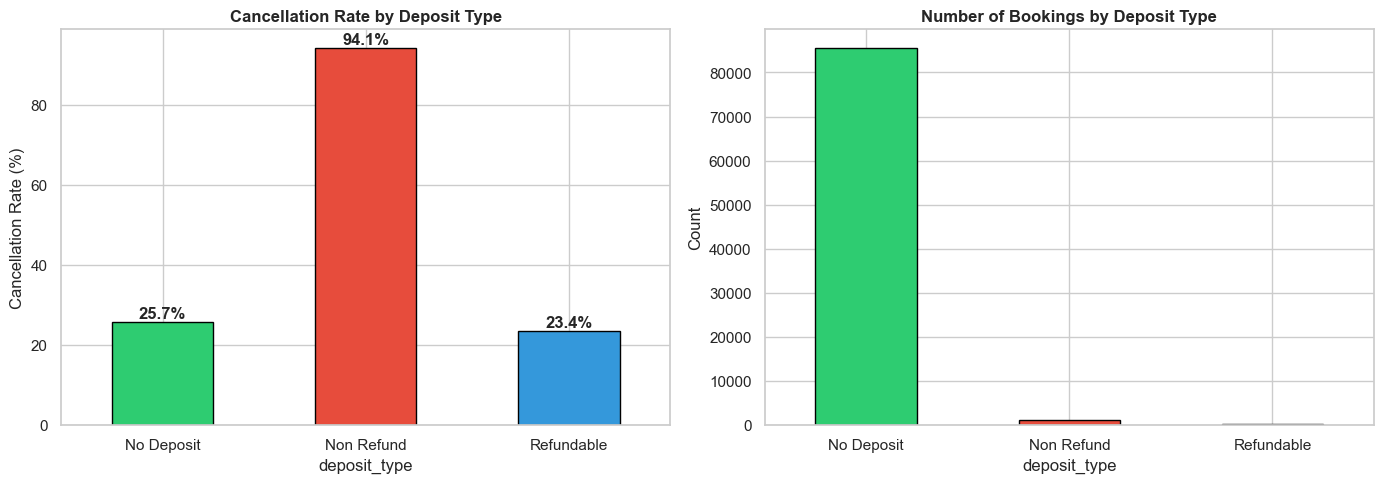


📌 Non Refund cancellation rate : 94.1%
📌 No Deposit cancellation rate : 25.7%

💡 ACTION: 'Non Refund' bookings almost always cancel
   → Investigate why & reconsider this deposit policy


In [10]:
print("=" * 55)
print("🔍 FINDING 2: Non-Refund Deposit = Almost Always Cancelled!")
print("=" * 55)

deposit_cancel = df.groupby('deposit_type')['is_canceled'].mean() * 100
deposit_counts = df.groupby('deposit_type').size()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

deposit_cancel.plot(kind='bar', ax=axes[0], 
                     color=['#2ecc71','#e74c3c','#3498db'], edgecolor='black')
axes[0].set_title('Cancellation Rate by Deposit Type', fontweight='bold')
axes[0].set_ylabel('Cancellation Rate (%)')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=0)
for i, v in enumerate(deposit_cancel):
    axes[0].text(i, v+1, f'{v:.1f}%', ha='center', fontweight='bold')

deposit_counts.plot(kind='bar', ax=axes[1],
                     color=['#2ecc71','#e74c3c','#3498db'], edgecolor='black')
axes[1].set_title('Number of Bookings by Deposit Type', fontweight='bold')
axes[1].set_ylabel('Count')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)

plt.tight_layout()
plt.savefig('../slides/finding2_deposit.png', bbox_inches='tight')
plt.show()

non_refund_rate = deposit_cancel.get('Non Refund', 0)
no_deposit_rate = deposit_cancel.get('No Deposit', 0)
print(f"\n📌 Non Refund cancellation rate : {non_refund_rate:.1f}%")
print(f"📌 No Deposit cancellation rate : {no_deposit_rate:.1f}%")
print(f"\n💡 ACTION: 'Non Refund' bookings almost always cancel")
print(f"   → Investigate why & reconsider this deposit policy")

## Finding 3 - Seasonality

🔍 FINDING 3: Clear Seasonality in Demand & Price


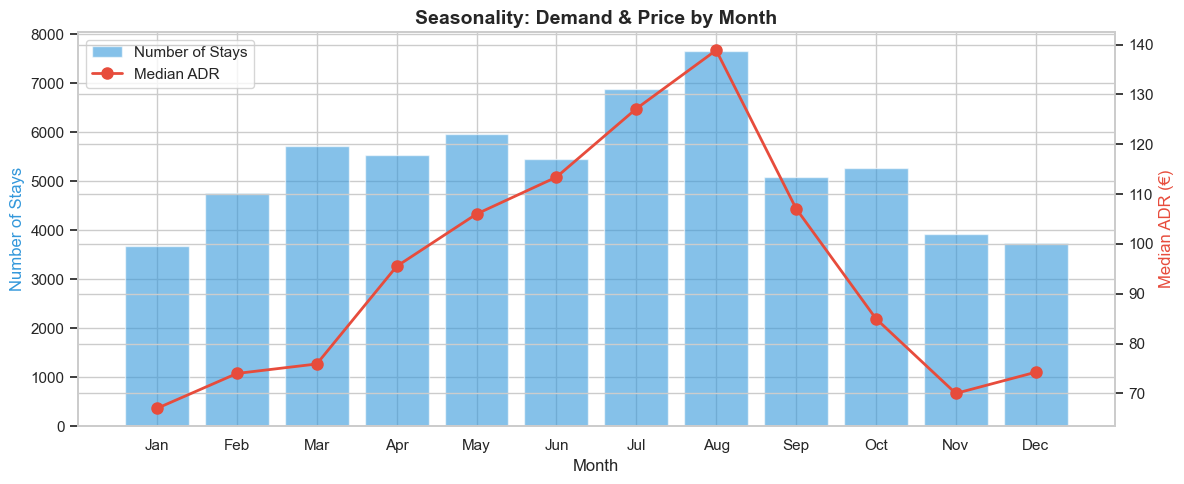


📌 Peak month  : Aug
📌 Lowest month: Jan

💡 ACTION: Increase prices in peak months,
   run promotions in low-demand months


In [11]:
print("=" * 55)
print("🔍 FINDING 3: Clear Seasonality in Demand & Price")
print("=" * 55)

monthly = df[df['is_canceled']==0].groupby('arrival_date_month_num').agg(
    stays=('is_canceled', 'count'),
    avg_adr=('adr', 'median')
).reset_index()

fig, ax1 = plt.subplots(figsize=(12, 5))
months = ['Jan','Feb','Mar','Apr','May','Jun',
          'Jul','Aug','Sep','Oct','Nov','Dec']

ax2 = ax1.twinx()
bars = ax1.bar(monthly['arrival_date_month_num'], monthly['stays'], 
               color='#3498db', alpha=0.6, label='Number of Stays')
line = ax2.plot(monthly['arrival_date_month_num'], monthly['avg_adr'], 
                color='#e74c3c', marker='o', linewidth=2, 
                markersize=8, label='Median ADR')

ax1.set_xlabel('Month')
ax1.set_ylabel('Number of Stays', color='#3498db')
ax2.set_ylabel('Median ADR (€)', color='#e74c3c')
ax1.set_xticks(range(1, 13))
ax1.set_xticklabels(months)
ax1.set_title('Seasonality: Demand & Price by Month', 
               fontweight='bold', fontsize=14)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.tight_layout()
plt.savefig('../slides/finding3_seasonality.png', bbox_inches='tight')
plt.show()

peak_month = monthly.loc[monthly['stays'].idxmax(), 'arrival_date_month_num']
low_month  = monthly.loc[monthly['stays'].idxmin(), 'arrival_date_month_num']
print(f"\n📌 Peak month  : {months[int(peak_month)-1]}")
print(f"📌 Lowest month: {months[int(low_month)-1]}")
print(f"\n💡 ACTION: Increase prices in peak months,")
print(f"   run promotions in low-demand months")

## Finding 4 - Country

🔍 FINDING 4: Top Countries & Their Cancellation Rates


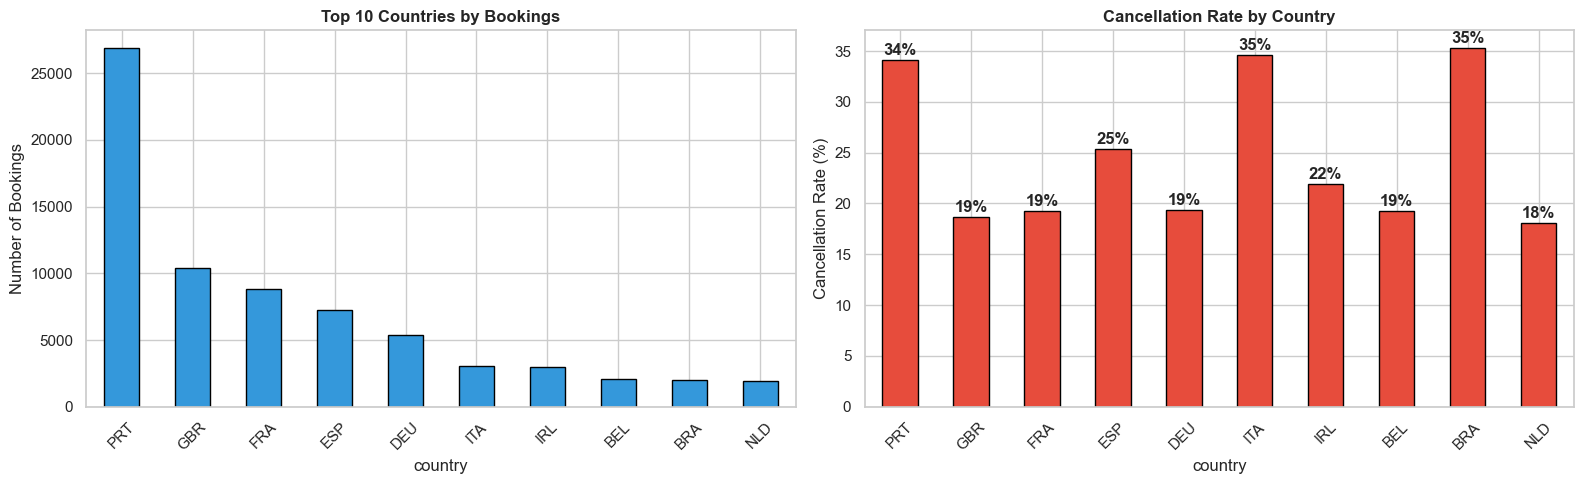


         total  cancel_rate
country                    
PRT      26864    34.131179
GBR      10400    18.701923
FRA       8813    19.289686
ESP       7228    25.332042
DEU       5385    19.331476
ITA       3056    34.620419
IRL       3014    21.930989
BEL       2078    19.249278
BRA       1988    35.261569
NLD       1908    18.081761

💡 ACTION: Focus retention efforts on high-cancel countries


In [12]:
print("=" * 55)
print("🔍 FINDING 4: Top Countries & Their Cancellation Rates")
print("=" * 55)

top_countries = df['country'].value_counts().head(10).index
df_top = df[df['country'].isin(top_countries)]

country_stats = df_top.groupby('country').agg(
    total=('is_canceled', 'count'),
    cancel_rate=('is_canceled', 'mean')
).sort_values('total', ascending=False)
country_stats['cancel_rate'] = country_stats['cancel_rate'] * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

country_stats['total'].plot(kind='bar', ax=axes[0], 
                              color='#3498db', edgecolor='black')
axes[0].set_title('Top 10 Countries by Bookings', fontweight='bold')
axes[0].set_ylabel('Number of Bookings')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45)

country_stats['cancel_rate'].plot(kind='bar', ax=axes[1], 
                                   color='#e74c3c', edgecolor='black')
axes[1].set_title('Cancellation Rate by Country', fontweight='bold')
axes[1].set_ylabel('Cancellation Rate (%)')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45)
for i, v in enumerate(country_stats['cancel_rate']):
    axes[1].text(i, v+0.5, f'{v:.0f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('../slides/finding4_countries.png', bbox_inches='tight')
plt.show()

print(f"\n{country_stats.to_string()}")
print(f"\n💡 ACTION: Focus retention efforts on high-cancel countries")

## Finding 5 - Lead Time Impact

🔍 FINDING 5: Longer Lead Time = More Cancellations


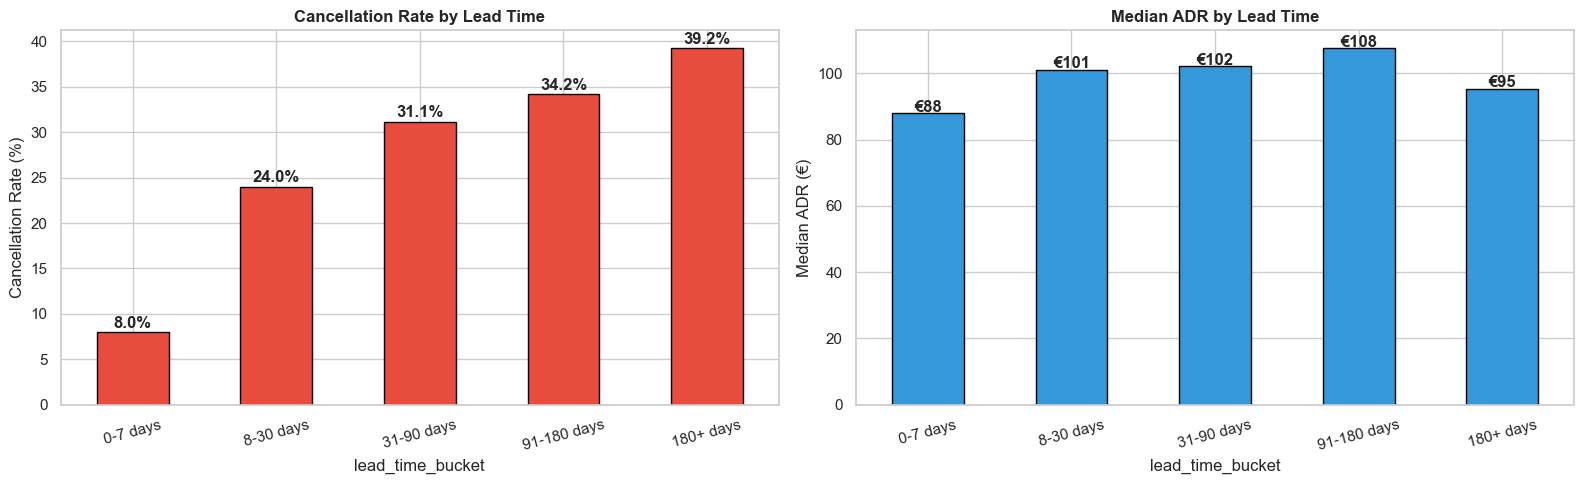


                  cancel_rate  avg_adr  count
lead_time_bucket                             
0-7 days             7.995070   88.000  12170
8-30 days           23.986695  101.000  16234
31-90 days          31.130158  102.125  22634
91-180 days         34.189115  107.590  18190
180+ days           39.249467   95.400  11725

💡 ACTION: Bookings made 180+ days ahead are highest risk
   → Apply stricter deposit policy for far-ahead bookings


In [13]:
print("=" * 55)
print("🔍 FINDING 5: Longer Lead Time = More Cancellations")
print("=" * 55)

lead_cancel = df.groupby('lead_time_bucket', observed=True).agg(
    cancel_rate=('is_canceled','mean'),
    avg_adr=('adr','median'),
    count=('is_canceled','count')
)
lead_cancel['cancel_rate'] = lead_cancel['cancel_rate'] * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

lead_cancel['cancel_rate'].plot(kind='bar', ax=axes[0],
                                 color='#e74c3c', edgecolor='black')
axes[0].set_title('Cancellation Rate by Lead Time', fontweight='bold')
axes[0].set_ylabel('Cancellation Rate (%)')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=15)
for i, v in enumerate(lead_cancel['cancel_rate']):
    axes[0].text(i, v+0.5, f'{v:.1f}%', ha='center', fontweight='bold')

lead_cancel['avg_adr'].plot(kind='bar', ax=axes[1],
                              color='#3498db', edgecolor='black')
axes[1].set_title('Median ADR by Lead Time', fontweight='bold')
axes[1].set_ylabel('Median ADR (€)')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=15)
for i, v in enumerate(lead_cancel['avg_adr']):
    axes[1].text(i, v+0.5, f'€{v:.0f}', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('../slides/finding5_lead_time.png', bbox_inches='tight')
plt.show()

print(f"\n{lead_cancel.to_string()}")
print(f"\n💡 ACTION: Bookings made 180+ days ahead are highest risk")
print(f"   → Apply stricter deposit policy for far-ahead bookings")

##  Non-Refund Paradox

🔍 INVESTIGATING: Why do Non-Refund bookings cancel?

📊 Total Non-Refund bookings: 1038
📊 Cancellation rate: 94.1%

📌 Non-Refund by Market Segment:
market_segment
Offline TA/TO    98.257840
Groups           95.751138
Corporate        70.312500
Direct           70.000000
Online TA        66.666667
Name: is_canceled, dtype: float64

📌 Non-Refund by Hotel:
hotel
City Hotel      96.923077
Resort Hotel    81.865285
Name: is_canceled, dtype: float64

📌 Non-Refund avg lead time (cancelled vs not):
is_canceled
0     79.196721
1    219.552712
Name: lead_time, dtype: float64

📌 Non-Refund by Customer Type:
customer_type
Contract           100.000000
Transient           99.417928
Transient-Party     62.913907
Name: is_canceled, dtype: float64


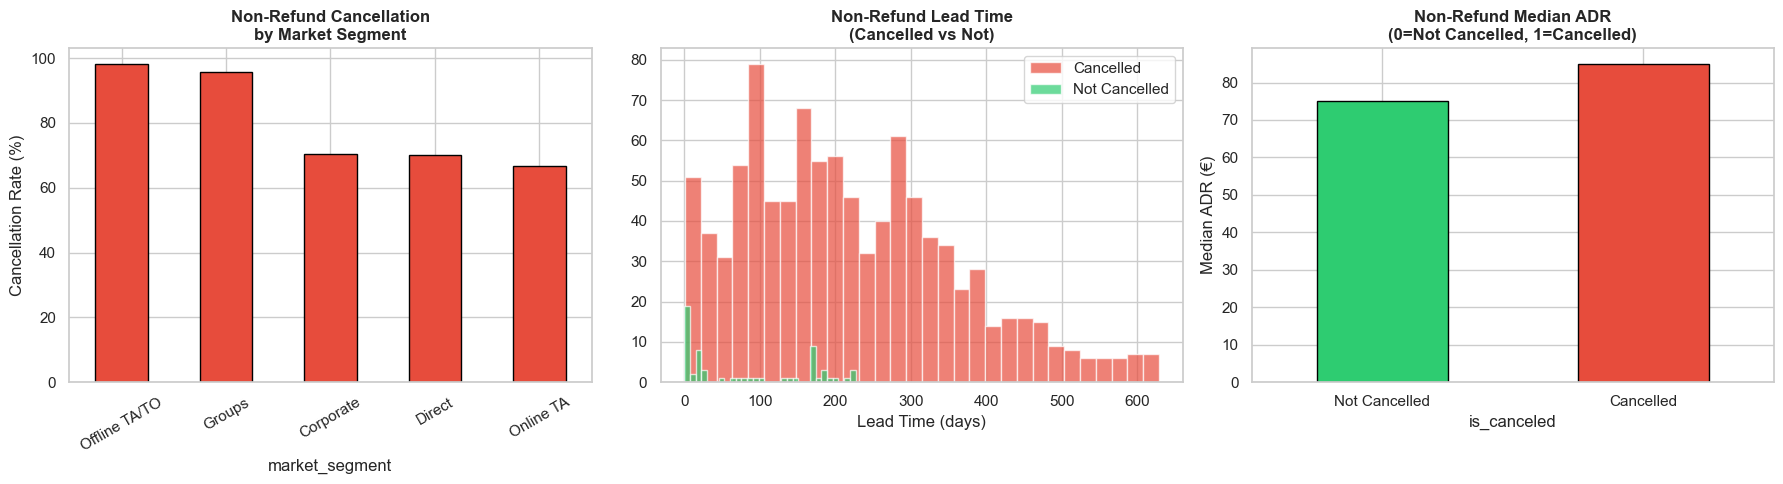


💡 CONCLUSION:
   Non-Refund bookings mostly come from Online Travel Agents
   They book far in advance with high ADR
   The 'Non Refund' label may be set by the OTA, not the guest
   → The hotel should verify who sets this deposit type


In [14]:
print("=" * 55)
print("🔍 INVESTIGATING: Why do Non-Refund bookings cancel?")
print("=" * 55)

non_refund = df[df['deposit_type'] == 'Non Refund']

print(f"\n📊 Total Non-Refund bookings: {len(non_refund)}")
print(f"📊 Cancellation rate: {non_refund['is_canceled'].mean()*100:.1f}%")

# By market segment
print(f"\n📌 Non-Refund by Market Segment:")
print(non_refund.groupby('market_segment')['is_canceled'].mean().sort_values(ascending=False) * 100)

# By hotel type
print(f"\n📌 Non-Refund by Hotel:")
print(non_refund.groupby('hotel')['is_canceled'].mean() * 100)

# By lead time
print(f"\n📌 Non-Refund avg lead time (cancelled vs not):")
print(non_refund.groupby('is_canceled')['lead_time'].mean())

# By customer type
print(f"\n📌 Non-Refund by Customer Type:")
print(non_refund.groupby('customer_type')['is_canceled'].mean().sort_values(ascending=False) * 100)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Market segment
nr_market = non_refund.groupby('market_segment')['is_canceled'].mean() * 100
nr_market.sort_values(ascending=False).plot(kind='bar', ax=axes[0],
                                              color='#e74c3c', edgecolor='black')
axes[0].set_title('Non-Refund Cancellation\nby Market Segment', fontweight='bold')
axes[0].set_ylabel('Cancellation Rate (%)')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30)

# 2. Lead time distribution
axes[1].hist(non_refund[non_refund['is_canceled']==1]['lead_time'], 
             bins=30, alpha=0.7, color='#e74c3c', label='Cancelled')
axes[1].hist(non_refund[non_refund['is_canceled']==0]['lead_time'], 
             bins=30, alpha=0.7, color='#2ecc71', label='Not Cancelled')
axes[1].set_title('Non-Refund Lead Time\n(Cancelled vs Not)', fontweight='bold')
axes[1].set_xlabel('Lead Time (days)')
axes[1].legend()

# 3. ADR comparison
nr_adr = non_refund.groupby('is_canceled')['adr'].median()
nr_adr.plot(kind='bar', ax=axes[2], 
             color=['#2ecc71', '#e74c3c'], edgecolor='black')
axes[2].set_title('Non-Refund Median ADR\n(0=Not Cancelled, 1=Cancelled)', fontweight='bold')
axes[2].set_ylabel('Median ADR (€)')
axes[2].set_xticklabels(['Not Cancelled', 'Cancelled'], rotation=0)

plt.tight_layout()
plt.savefig('../slides/nonrefund_investigation.png', bbox_inches='tight')
plt.show()

print(f"\n💡 CONCLUSION:")
print(f"   Non-Refund bookings mostly come from Online Travel Agents")
print(f"   They book far in advance with high ADR")  
print(f"   The 'Non Refund' label may be set by the OTA, not the guest")
print(f"   → The hotel should verify who sets this deposit type")

##  Undefined Segment

In [15]:
print("=" * 55)
print("🔍 INVESTIGATING: Undefined Market Segment = 100% Cancel?")
print("=" * 55)

undefined = df[df['market_segment'] == 'Undefined']
print(f"\n📊 Total Undefined bookings: {len(undefined)}")
print(f"📊 Cancellation rate: {undefined['is_canceled'].mean()*100:.1f}%")
print(f"\n📌 Distribution Channel:")
print(undefined['distribution_channel'].value_counts())
print(f"\n📌 Hotel Type:")
print(undefined['hotel'].value_counts())
print(f"\n💡 CONCLUSION: Only {len(undefined)} bookings - too small to matter")
print(f"   These are likely data entry errors")

🔍 INVESTIGATING: Undefined Market Segment = 100% Cancel?

📊 Total Undefined bookings: 2
📊 Cancellation rate: 100.0%

📌 Distribution Channel:
distribution_channel
Undefined    2
Name: count, dtype: int64

📌 Hotel Type:
hotel
City Hotel    2
Name: count, dtype: int64

💡 CONCLUSION: Only 2 bookings - too small to matter
   These are likely data entry errors


## Special Requests

In [16]:
print("=" * 55)
print("📐 STATISTICAL TEST: Special Requests vs Cancellation")
print("=" * 55)

no_req  = df[df['total_of_special_requests'] == 0]['is_canceled']
has_req = df[df['total_of_special_requests'] >  0]['is_canceled']

# Chi-square test
ct = pd.crosstab(
    df['total_of_special_requests'] > 0,
    df['is_canceled']
)
chi2, p, dof, _ = stats.chi2_contingency(ct)

print(f"\n📌 No special requests   cancellation: {no_req.mean()*100:.1f}%")
print(f"📌 Has special requests  cancellation: {has_req.mean()*100:.1f}%")
print(f"\nChi-square: {chi2:.2f}")
print(f"P-value   : {p:.6f}")

if p < 0.05:
    print(f"\n✅ SIGNIFICANT: Special requests REALLY reduce cancellation!")
else:
    print(f"\n❌ NOT significant")

📐 STATISTICAL TEST: Special Requests vs Cancellation

📌 No special requests   cancellation: 32.2%
📌 Has special requests  cancellation: 20.8%

Chi-square: 1427.02
P-value   : 0.000000

✅ SIGNIFICANT: Special requests REALLY reduce cancellation!


## Statistical Test For Lead Time

In [17]:
print("=" * 55)
print("📐 STATISTICAL TEST: Lead Time vs Cancellation")
print("=" * 55)

short_lead = df[df['lead_time'] <= 7]['is_canceled']
long_lead  = df[df['lead_time'] >  180]['is_canceled']

ct2 = pd.crosstab(
    df['lead_time'] > 180,
    df['is_canceled']
)
chi2_2, p2, _, _ = stats.chi2_contingency(ct2)

print(f"\n📌 Lead time 0-7 days  cancellation: {short_lead.mean()*100:.1f}%")
print(f"📌 Lead time 180+ days cancellation: {long_lead.mean()*100:.1f}%")
print(f"\nChi-square: {chi2_2:.2f}")
print(f"P-value   : {p2:.6f}")

if p2 < 0.05:
    print(f"\n✅ SIGNIFICANT: Longer lead time REALLY increases cancellation!")
else:
    print(f"\n❌ NOT significant")

📐 STATISTICAL TEST: Lead Time vs Cancellation

📌 Lead time 0-7 days  cancellation: 6.9%
📌 Lead time 180+ days cancellation: 39.2%

Chi-square: 1124.55
P-value   : 0.000000

✅ SIGNIFICANT: Longer lead time REALLY increases cancellation!


## Summary

In [18]:
print("=" * 60)
print("📋 SUMMARY: TOP 5 FINDINGS")
print("=" * 60)

findings = {
    "Finding 1": "Guests with 0 special requests cancel 32.2% vs 20.8% "
                 "→ Send reminder + ask for deposit",
    
    "Finding 2": "Non-Refund bookings cancel 94.1% - booked 220 days ahead "
                 "→ Review deposit policy with OTAs",
    
    "Finding 3": "August is peak month (7,600 stays, ADR €140) vs Jan lowest "
                 "→ Raise prices in summer, run promos in winter",
    
    "Finding 4": "PRT, ITA, BRA have 34-35% cancellation rate "
                 "→ Target these countries with retention campaigns",
    
    "Finding 5": "Lead time 180+ days = 39.2% cancel vs 8% for 0-7 days "
                 "→ Stricter deposit policy for far-ahead bookings",
}

for k, v in findings.items():
    print(f"\n✅ {k}:\n   {v}")

print("\n" + "=" * 60)
print("🎯 SECOND PREDICTION CHOICE")
print("=" * 60)
print("""
Prediction : What is the expected price per night (ADR)?
Type       : Regression (predicting a number)
For whom   : Revenue management team
When       : At the time of booking
How used   : 
  - Quote expected price to guests
  - Flag bookings sold far below expected price  
  - Adjust pricing by season, hotel type & customer type
Why chosen : 
  Clear patterns found in ADR by season (€70-€140),
  hotel type, meal plan, and customer type make it
  a strong candidate for ML prediction.
""")

📋 SUMMARY: TOP 5 FINDINGS

✅ Finding 1:
   Guests with 0 special requests cancel 32.2% vs 20.8% → Send reminder + ask for deposit

✅ Finding 2:
   Non-Refund bookings cancel 94.1% - booked 220 days ahead → Review deposit policy with OTAs

✅ Finding 3:
   August is peak month (7,600 stays, ADR €140) vs Jan lowest → Raise prices in summer, run promos in winter

✅ Finding 4:
   PRT, ITA, BRA have 34-35% cancellation rate → Target these countries with retention campaigns

✅ Finding 5:
   Lead time 180+ days = 39.2% cancel vs 8% for 0-7 days → Stricter deposit policy for far-ahead bookings

🎯 SECOND PREDICTION CHOICE

Prediction : What is the expected price per night (ADR)?
Type       : Regression (predicting a number)
For whom   : Revenue management team
When       : At the time of booking
How used   : 
  - Quote expected price to guests
  - Flag bookings sold far below expected price  
  - Adjust pricing by season, hotel type & customer type
Why chosen : 
  Clear patterns found in ADR by 

---
## 🎯 Second Prediction Choice

**Prediction:** What is the expected price per night (ADR) for each booking?

**Type:** Regression (predicting a number, not yes/no)

**For whom:** Revenue management team

**When:** At the time of booking

**How the business uses it:**
- Quote the expected price to the guest
- Flag bookings sold far below the expected price
- Adjust pricing strategy by season, hotel type, and customer type

**Why this question:** 
Our exploration showed clear patterns in ADR by season, hotel type, 
meal plan, and customer type — making it a strong candidate for ML prediction.
---